# Cooling equipment sensor-fault detection

Deep Learning Project — Section B. Rishabh Srivastava, Mitul Seth, Madhav Mittal.

This notebook examines the executed, frozen LSTM benchmark. The primary task is outdoor-air sensor-bias detection in an operating **simulated** air-handling unit. It does not establish datacenter deployment or future-fault forecasting.

The data comes from [LBNL AFDD collection](https://data.openei.org/submissions/910), DOI 10.25984/1824861. The source inventory verifies native condition labels. The M100 study remains separate supporting research.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import torch
ROOT = Path.cwd()
assert (ROOT / "results/hvac_v1/experiment_plan.json").exists(), "Run this notebook from the project folder"
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results/hvac_v1"
torch.set_num_threads(4)
plan = json.loads((R / "experiment_plan.json").read_text())
print(plan["task"])
print("Source:", plan["source_doi"])

Operating simulated air-handling-unit outdoor-air sensor-bias detection
Source: 10.25984/1824861


## Whole-season separation

Winter/spring train, summer validates, autumn tests. Whole source days and scenario blocks stay within one partition. Every input contains 30 consecutive occupied, fan-on minutes, with no cross-day or cross-gap histories. Nights and nonoperating days are disclosed as unscored. Do not use a shuffled overlapping-window split.

In [2]:
cohorts = pd.DataFrame(plan["cohorts"]).T[["raw_days", "scored_days", "windows", "faulty"]]
print(cohorts.to_string())
print("Features:", len(plan["model_features"]))
print("Calendar, labels and bias intensity are not model inputs.")

           raw_days scored_days windows faulty
train            91          77   61187  52446
validation       49          42   33432  28656
test             49          42   33432  28656
Features: 32
Calendar, labels and bias intensity are not model inputs.


## Saved model and training choices

13 raw measurements/commands + 6 consistency features + 13 missing indicators = 32 channels. Negative outdoor Fahrenheit readings stay valid. Filling, median fallback and scaling use the declared causal/training-only rules. Training positive weight is about 1/6 because faults outnumber normal examples. This balances loss without changing evaluation prevalence.

In [3]:
from dccad.supervised import LSTMClassifier
checkpoint = torch.load(R / "lstm_seed_42/model.pt", map_location="cpu", weights_only=True)
model = LSTMClassifier(len(checkpoint["features"]), checkpoint["hidden"], checkpoint["dropout"])
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
print("Primary training seed: 42, fixed before autumn evaluation")

LSTMClassifier(
  (encoder): LSTM(32, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 8993
Primary training seed: 42, fixed before autumn evaluation


## Final results at frozen validation policies

The fixed primary is seed 42, even though seed 7 has higher test accuracy. These are separate seasonal benchmark results, not direct improvements to the M100 population. Experimental fault prevalence is 85.71%; an all-fault predictor would have 85.71% accuracy and 100% FPR.

In [4]:
comparison = pd.read_csv(R / "test_model_comparison.csv")
print(comparison[["model", "accuracy", "precision", "recall", "f1", "average_precision", "false_positive_rate", "fp", "fn"]].to_string(index=False))
summary = json.loads((R / "test_summary.json").read_text())
print("No post-test tuning:", not summary["post_test_tuning"])

        model  accuracy  precision   recall       f1  average_precision  false_positive_rate  fp   fn
  lstm_seed_7  0.966589   0.997327 0.963603 0.980175           0.998806             0.015494  74 1043
 lstm_seed_42  0.928183   0.997386 0.918621 0.956384           0.996239             0.014447  69 2332
lstm_seed_123  0.855498   0.997079 0.833857 0.908193           0.997318             0.014657  70 4761
     boosting  0.760439   1.000000 0.720512 0.837556           0.991373             0.000000   0 8009
No post-test tuning: True


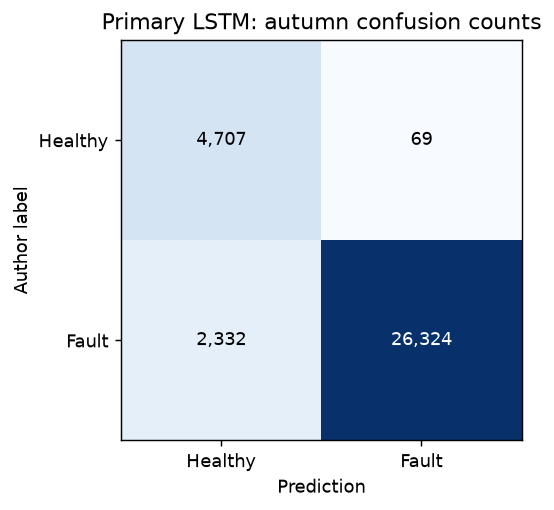

In [5]:
import matplotlib.pyplot as plt
m = summary["primary_test"]
matrix = [[m["tn"], m["fp"]], [m["fn"], m["tp"]]]
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matrix[i][j]:,}", ha="center", va="center", color="white" if matrix[i][j]>14000 else "black")
ax.set_xticks([0,1], ["Healthy", "Fault"])
ax.set_yticks([0,1], ["Healthy", "Fault"])
ax.set(xlabel="Prediction", ylabel="Author label", title="Primary LSTM: autumn confusion counts")
plt.show()

## False alarms, severity and coverage

The primary model has 69 false readings in one burst. FPR=FP/(FP+TN) differs from false discovery ratio=FP/(TP+FP). FPR 1.44% exceeds the original 1% goal. The model detects 35/36 observable fault days and 35/42 total fault days; six fault days have no eligible operating window.

In [6]:
print(pd.read_csv(R / "test_by_severity.csv").to_string(index=False))
evidence = json.loads((R / "evidence_summary.json").read_text())
print("Median minutes from midnight imposition:", evidence["source_midnight_median_delay_minutes"])
print("Median minutes from first eligible endpoint:", evidence["first_eligible_median_delay_minutes"])
print("Original target gate:", evidence["test_targets_met"])

 bias_c  scored_days   tp  fp   fn   tn   recall      fpr  detected_days
   -4.0            6 4764   0   12    0 0.997487      NaN              6
   -2.0            6 4590   0  186    0 0.961055      NaN              6
   -1.0            6 3749   0 1027    0 0.784966      NaN              5
    0.0            6    0  69    0 4707      NaN 0.014447              0
    1.0            6 4176   0  600    0 0.874372      NaN              6
    2.0            6 4334   0  442    0 0.907454      NaN              6
    4.0            6 4711   0   65    0 0.986390      NaN              6
Median minutes from midnight imposition: 392.0
Median minutes from first eligible endpoint: 2.0
Original target gate: {'precision': True, 'recall': True, 'fpr': False, 'false_bursts': True, 'observable_fault_days': True}


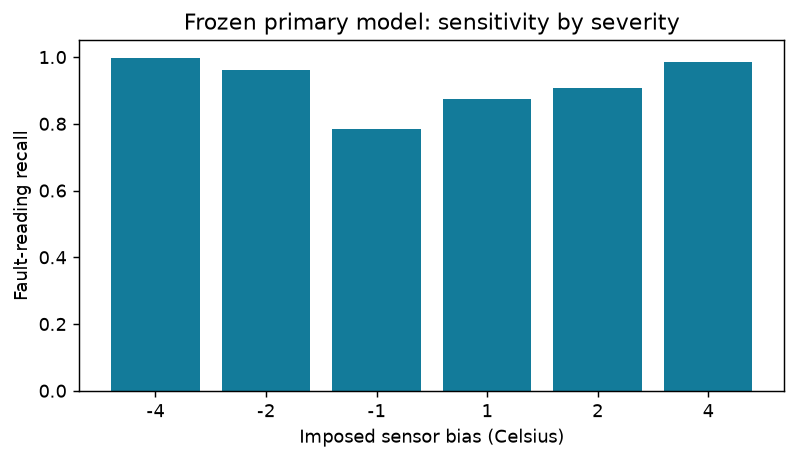

In [7]:
severity = pd.read_csv(R / "test_by_severity.csv")
faults = severity[severity.bias_c != 0]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(faults.bias_c.astype(int).astype(str), faults.recall, color="#137B9A")
ax.set(xlabel="Imposed sensor bias (Celsius)", ylabel="Fault-reading recall", ylim=(0, 1.05), title="Frozen primary model: sensitivity by severity")
plt.show()

## Fresh inference

Scores are uncalibrated logits. A single window supplies one endpoint; the frozen two-of-three alarm requires three consecutive scored minutes. Inference uses only saved preprocessing and sensor inputs, never the reference label.

In [8]:
from dccad.hvac_inference import score_window
window = pd.read_csv(R / "lstm_seed_42/example_window.csv")
score = score_window(R / "lstm_seed_42", window)
policy = json.loads((R / "frozen_model.json").read_text())["policy"]
expected = json.loads((R / "lstm_seed_42/example_metadata.json").read_text())["expected_score"]
assert abs(score - expected) < 1e-4
print("Fresh endpoint score:", score)
print("Frozen threshold/rule:", policy)
print("One endpoint cannot confirm persistent alarm state.")

Fresh endpoint score: 0.050426334142684937
Frozen threshold/rule: {'threshold': 6.967112064361571, 'rule': 'two_of_three', 'cadence_minutes': 1, 'reset': 'day/unit/gap'}
One endpoint cannot confirm persistent alarm state.


## Reproduction and limits

Run from the project directory:
```text
python scripts/prepare_hvac.py
python scripts/train_hvac.py
python scripts/verify_hvac.py --validation-only
python scripts/evaluate_hvac.py
python scripts/verify_hvac.py
python scripts/build_hvac_evidence.py
streamlit run dashboard/app.py
```

The final evaluation script returns saved results on rerun. A revised model needs a new version and a fresh evaluation design; do not tune against the inspected autumn season.

One simulated unit, one fault family and one healthy scenario week per validation/test season limit generalization. Adjacent readings/days are correlated. There is no claimed deployment-prevalence or independent-equipment reliability estimate. Inspect the report for successful, missed and false-alarm cases.